# 02 - Baseline: TF-IDF (char + word) + LinearSVC
- Văn bản cột `text_baseline`
- chạy `python -m src.models.baseline`

In [9]:
import re, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

from src.config import (LABELS, DATA_DIR, MODELS_DIR, RESULTS_METRICS, RESULTS_FIGURES, RESULTS_PREDICTIONS, PREPROCESS_PRESETS)
print("ROOT =", ROOT)

ROOT = c:\Users\this pc\Downloads\7_projectNLP


In [10]:
from src.config import BASELINE
print("Preset tiền xử lý:", PREPROCESS_PRESETS["baseline"])
print(json.dumps(BASELINE,ensure_ascii=False, indent=2))

Preset tiền xử lý: {'lower': True, 'repeat': True, 'teencode': True, 'emoji': 'token', 'segment': False}
{
  "char": {
    "analyzer": "char_wb",
    "ngram_range": [
      2,
      5
    ],
    "min_df": 2,
    "max_features": 300000
  },
  "word": {
    "analyzer": "word",
    "ngram_range": [
      1,
      3
    ],
    "min_df": 2,
    "max_features": 300000
  },
  "c_grid": [
    0.1,
    0.3,
    1.0,
    2.0
  ]
}


## 1. Nạp kết quả

In [11]:
metrics_path = RESULTS_METRICS / "baseline.json"
assert metrics_path.exists(), "Chưa có kết quả. Hãy chạy baseline"
print("Đã có kết quả:", metrics_path.name)

Đã có kết quả: baseline.json


## 2. Kết quả

baseline: val macro-F1 = 0.6771 | test macro-F1 = 0.6705 | test acc = 0.8777
{'best_C': 1.0, 'n_features': 89897, 'seconds': 14.0}


,precision,recall,f1,support
BÌNH THƯỜNG,0.9351,0.9500,0.9425,2458.0
XÚC PHẠM,0.4848,0.3980,0.4372,201.0
THÙ GHÉT,0.6347,0.6288,0.6317,326.0


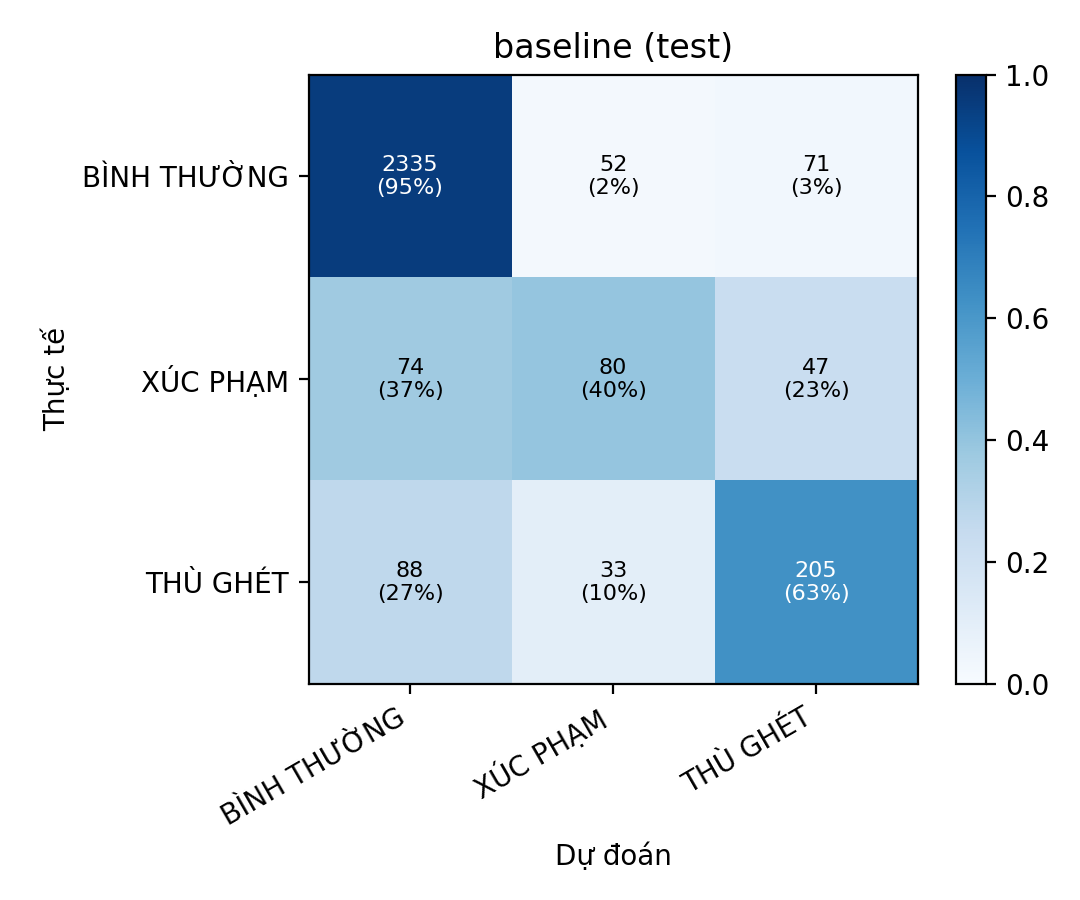

In [12]:
from src.evaluate import show_results
show_results("baseline") # macro-F1, bảng theo lớp và confusion matrix của test

In [13]:
r = json.load(open(metrics_path, encoding="utf-8"))
metrics = ("accuracy", "macro_f1", "weighted_f1")
val_metrics = {k: r["val"][k] for k in metrics}
test_metrics = {k: r["test"][k] for k in metrics}

overall = pd.DataFrame({
    "val": val_metrics,
    "test": test_metrics
}).round(4)
display(overall)

print("Chênh lệch macro-f1 (val - test):", round(r["val"]["macro_f1"] - r["test"]["macro_f1"], 4))
for s in ("val", "test"):
    print(f"  ({s})")
    display(pd.DataFrame(r[s]["per_class"]).T.round(4))
print({k: v for k, v in r["extra"].items()})

,val,test
accuracy,0.8808,0.8777
macro_f1,0.6771,0.6705
weighted_f1,0.8779,0.8745


Chênh lệch macro-f1 (val - test): 0.0067
  (val)


,precision,recall,f1,support
BÌNH THƯỜNG,0.9383,0.9523,0.9452,2474.0
XÚC PHẠM,0.5060,0.4208,0.4595,202.0
THÙ GHÉT,0.6296,0.6239,0.6267,327.0


  (test)


,precision,recall,f1,support
BÌNH THƯỜNG,0.9351,0.9500,0.9425,2458.0
XÚC PHẠM,0.4848,0.3980,0.4372,201.0
THÙ GHÉT,0.6347,0.6288,0.6317,326.0


{'best_C': 1.0, 'model': 'LinearSVC (loss=hinge)', 'n_features': 89897, 'seconds': 14.0}


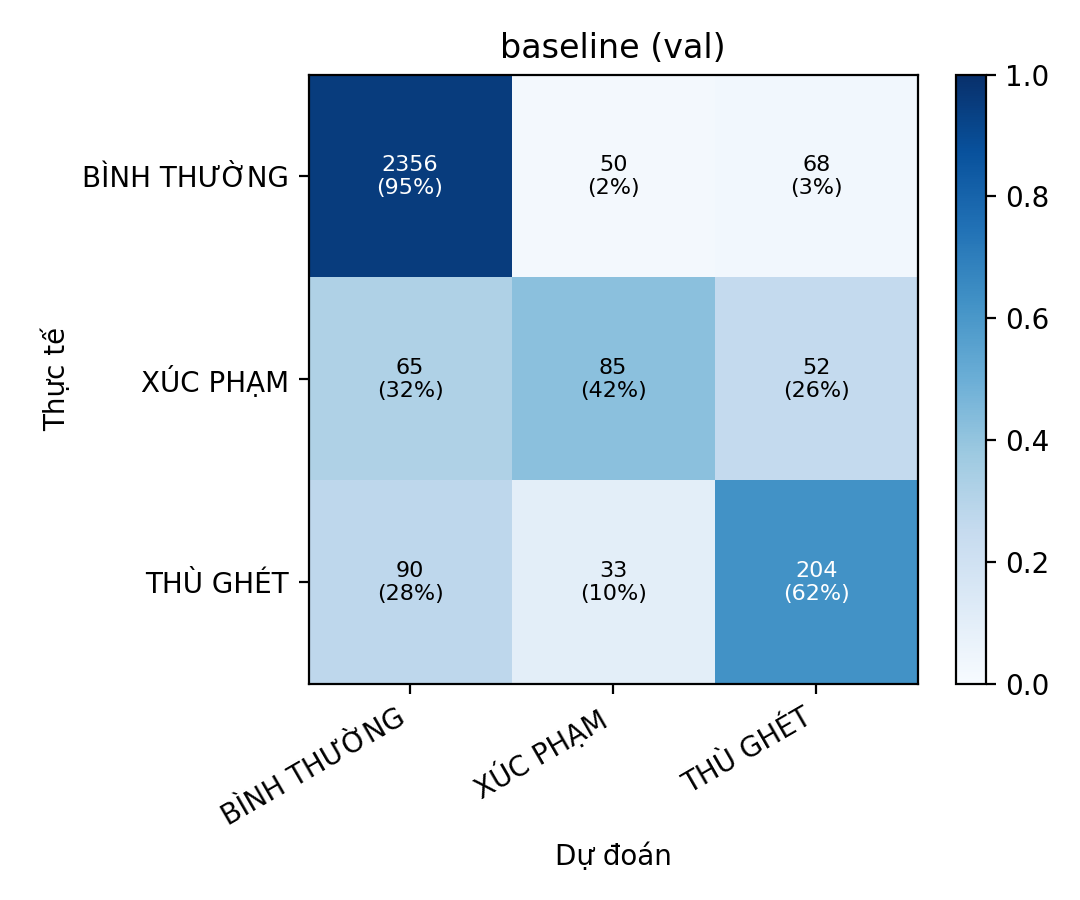

In [14]:
# confusion matrix của val
display(Image(filename=str(RESULTS_FIGURES / "cm_baseline_val.png")))

## 3. Độ tin cậy (confidence)

In [15]:
pred = pd.read_csv(RESULTS_PREDICTIONS / "baseline_test.csv")
prob_cols = [f"p_{LABELS[i]}" for i in sorted(LABELS)]

print("Độ tin cậy trung bình khi đoán đúng:", round(pred[pred.correct].confidence.mean(), 3))
print("Độ tin cậy trung bình khi đoán sai :", round(pred[~pred.correct].confidence.mean(), 3))
print("Số câu sai có độ tin cậy > 0.8      :", int(((~pred.correct) & (pred.confidence > 0.8)).sum()), "/", int((~pred.correct).sum()))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist([pred[pred.correct].confidence, pred[~pred.correct].confidence], bins=20, label=["đúng", "sai"], stacked=True)
ax.set_xlabel("độ tin cậy")
ax.set_ylabel("số câu")
ax.legend()
ax.set_title("Baseline – phân bố độ tin cậy trên test")
plt.tight_layout()
plt.show()

Độ tin cậy trung bình khi đoán đúng: 0.911
Độ tin cậy trung bình khi đoán sai : 0.637
Số câu sai có độ tin cậy > 0.8      : 113 / 365


C:\Users\this pc\AppData\Local\Temp\ipykernel_25788\38765239.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. Đặc trưng nổi bật của từng lớp

In [16]:
import joblib

model = joblib.load(MODELS_DIR / "baseline.joblib")
names = model.vector.get_feature_names_out()
coef = model.svm.coef_           
for row, cid in enumerate(model.svm.classes_):
    top = np.argsort(coef[row])[::-1][:20]
    print(f"{LABELS[int(cid)]}:", [names[i] for i in top], "\n")

BÌNH THƯỜNG: ['word__cái này', 'word__vãi lồn', 'word__được vãi lồn', 'word__được vãi', 'word__cái gì', 'word__hay vãi', 'word__thịt chó', 'word__cho con', 'word__giống vãi lồn', 'word__như này', 'word__hay vãi lồn', 'char__ :', 'word__như vậy', 'word__con gái', 'char__lo ', 'word__mọi người', 'word__con so', 'word__đàn ông', 'word__hà', 'word__ngô'] 

XÚC PHẠM: ['char__” ', 'word__khổ quá', 'word__đồ giả', 'word__đéo', 'word__lòn', 'word__con cho', 'word__dơ quá', 'word__haha trend', 'word__súc sinh', 'word__tâm thần', 'word__hoàng văn', 'word__thật nhỉ', 'word__quỷ rồi', 'word__hay người', 'word__buồi', 'word__đờ mờ', 'word__nghiệp quật', 'word__xx', 'word__quần què', 'word__cái nước'] 

THÙ GHÉT: ['char__ b', 'word__ngu', 'word__đang chờ', 'word__thầy lol', 'word__con này', 'word__tâm thần', 'word__tiệp', 'word__cho hay', 'word__chơi bẩn', 'word__dữ quá', 'word__cô hồn', 'word__bò đỏ', 'word__mịe', 'word__đi gia', 'word__trung tâm', 'word__ăn cứt', 'word__dlv', 'word__giết nó', 'wor